In [10]:
import pandas as pd
df = pd.read_csv("breast_cancer.csv")
df['diagnosis'] = df['diagnosis'].map({'malignant': 1, 'benign': 0}) #
df = df.rename(columns={'concave points': 'concave_points'})
print(df)

     radius  concave_points  texture  diagnosis
0    25.380          0.2654    17.33          1
1    24.990          0.1860    23.41          1
2    23.570          0.2430    25.53          1
3    14.910          0.2575    26.50          1
4    22.540          0.1625    16.67          1
..      ...             ...      ...        ...
564  25.450          0.2216    26.40          1
565  23.690          0.1628    38.25          1
566  18.980          0.1418    34.12          1
567  25.740          0.2650    39.42          1
568   9.456          0.0000    30.37          0

[569 rows x 4 columns]


In [14]:
print(df['diagnosis'].value_counts())      # patients with and without breast cancer
print(df[['radius', 'concave_points', 'texture']].describe())

diagnosis
0    357
1    212
Name: count, dtype: int64
           radius  concave_points     texture
count  569.000000      569.000000  569.000000
mean    16.269190        0.114606   25.677223
std      4.833242        0.065732    6.146258
min      7.930000        0.000000   12.020000
25%     13.010000        0.064930   21.080000
50%     14.970000        0.099930   25.410000
75%     18.790000        0.161400   29.720000
max     36.040000        0.291000   49.540000


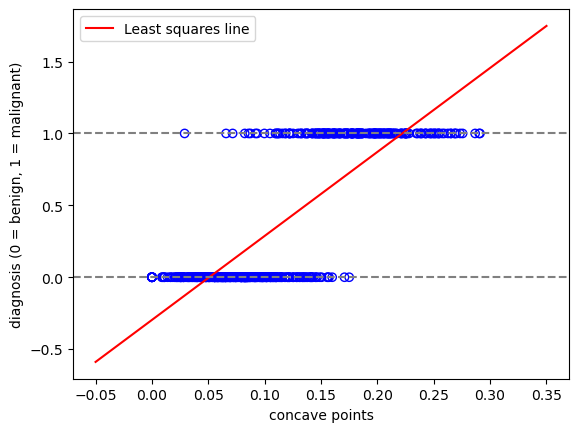

In [2]:
import numpy as np
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
import pandas as pd

model = smf.ols('diagnosis ~ concave_points', data=df).fit()

grid = pd.DataFrame({'concave_points': np.linspace(-0.05, 0.35, 100)})

plt.scatter(df['concave_points'], df['diagnosis'], facecolors='none', edgecolors='blue')
plt.plot(grid['concave_points'], model.predict(grid), color='red', label='Least squares line')
plt.axhline(0, color='gray', linestyle='--')
plt.axhline(1, color='gray', linestyle='--')
plt.xlabel('concave points')
plt.ylabel('diagnosis (0 = benign, 1 = malignant)')
plt.legend()
plt.show()

Optimization terminated successfully.
         Current function value: 0.220080
         Iterations 8


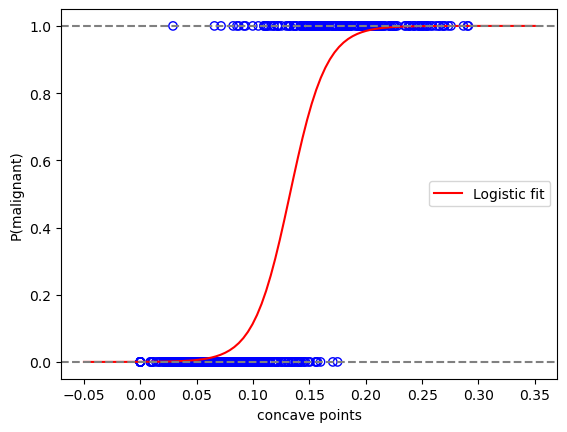

In [3]:
model = smf.logit('diagnosis ~ concave_points', data=df).fit()

grid = pd.DataFrame({'concave_points': np.linspace(-0.05, 0.35, 100)})

plt.scatter(df['concave_points'], df['diagnosis'], facecolors='none', edgecolors='blue')
plt.plot(grid['concave_points'], model.predict(grid), color='red', label='Logistic fit')
plt.axhline(0, color='gray', linestyle='--')
plt.axhline(1, color='gray', linestyle='--')
plt.xlabel('concave points')
plt.ylabel('P(malignant)')
plt.legend()
plt.show()

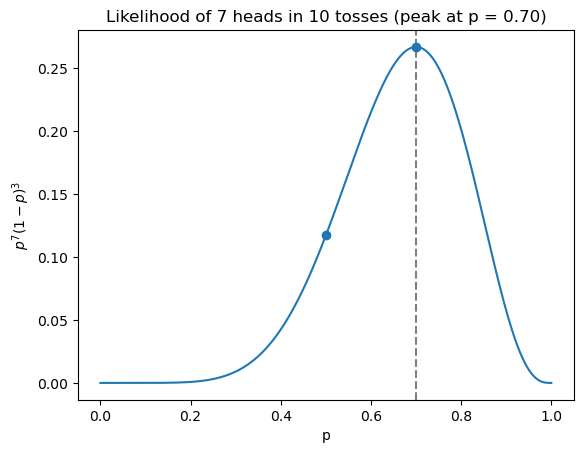

In [4]:
from math import comb
p = np.linspace(0, 1, 501)
L = comb(10, 7) * p**7 * (1 - p)**3      # likelihood of 7 heads in 10 tosses

p_hat = p[np.argmax(L)]                  # MLE (≈ 0.7)

plt.plot(p, L)
plt.axvline(p_hat, linestyle="--", color="gray")
plt.scatter([0.5, 0.7], [comb(10, 7) * 0.5**10, comb(10, 7) * 0.7**7 * 0.3**3], zorder=3)
plt.xlabel("p")
plt.ylabel(r"$p^7(1-p)^3$")
plt.title(f"Likelihood of 7 heads in 10 tosses (peak at p = {p_hat:.2f})")
plt.show()

In [15]:
# Run the Logistic Regression
import statsmodels.formula.api as smf
model = smf.logit('diagnosis ~ concave_points + radius + texture', data=df).fit()
print(model.summary())

Optimization terminated successfully.
         Current function value: 0.089356
         Iterations 10
                           Logit Regression Results                           
Dep. Variable:              diagnosis   No. Observations:                  569
Model:                          Logit   Df Residuals:                      565
Method:                           MLE   Df Model:                            3
Date:                Wed, 21 Oct 2026   Pseudo R-squ.:                  0.8647
Time:                        14:59:14   Log-Likelihood:                -50.843
converged:                       True   LL-Null:                       -375.72
Covariance Type:            nonrobust   LLR p-value:                1.648e-140
                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept        -32.8621      4.374     -7.513      0.000     -41.435     -24.289
concave_points  

In [21]:
# odds ratios for a one-unit increase
print(np.exp(model.params[['radius', 'texture']]))

# odds ratio for a 10 bpm increase in thalach
print(np.exp(0.1 * model.params['concave_points']))

# Interpretration?

radius     3.138000
texture    1.320754
dtype: float64
169.6416843671158


In [23]:
# Confidence Interval for Odd-Ratio
print(np.exp(model.conf_int()))

                           0             1
Intercept       1.011554e-18  2.827107e-11
concave_points  3.726755e+14  1.045492e+30
radius          2.190773e+00  4.494779e+00
texture         1.190891e+00  1.464778e+00


In [28]:
# Prediction
new = pd.DataFrame({'concave_points': [0.114606], 'radius': [16.269190], 'texture': [25.677223]})
print(model.predict(new)[0])

0.22619597015644607


In [6]:
# AIC & BIC comparison
model1 = smf.logit('diagnosis ~ concave_points + radius + texture', data=df).fit()
model2 = smf.logit('diagnosis ~ concave_points + texture', data=df).fit()

print("model", 1, "AIC: ", model1.aic, "BIC: ", model1.bic)
print("model", 2, "AIC: ", model2.aic, "BIC: ", model2.bic)

Optimization terminated successfully.
         Current function value: 0.089356
         Iterations 10
Optimization terminated successfully.
         Current function value: 0.182438
         Iterations 9
model 1 AIC:  109.68680382412884 BIC:  127.06232556063416
model 2 AIC:  213.61476514787563 BIC:  226.64640645025463


In [7]:
import pandas as pd

df['p_hat'] = model.predict(df)
df['pred'] = (df['p_hat'] > 0.8).astype(int) # You can change to 0.5, 0.2, etc

table = pd.crosstab(df['diagnosis'], df['pred'],
                    rownames=['Actual'], colnames=['Predicted'])
table = table.reindex(index=[1, 0], columns=[1, 0])
print(table)

Predicted    1    0
Actual             
1          188   24
0            1  356


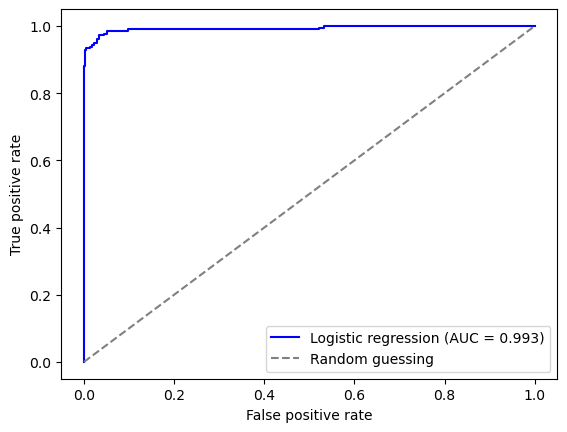

In [8]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

p_hat = model.predict(df)                       # predicted P(malignant)

fpr, tpr, thresholds = roc_curve(df['diagnosis'], p_hat)
auc = roc_auc_score(df['diagnosis'], p_hat)

plt.plot(fpr, tpr, color='blue', label=f'Logistic regression (AUC = {auc:.3f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', label='Random guessing')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.legend()
plt.show()